# Clustering y Despliegue de ML — Ejercicios 1.1 a 4.2
**Ingeniería del Conocimiento (ISO56B) — UNCP, 2026-II**

**ESTUDIANTE:** Espinoza Inga Deysi
| Nivel | Ejercicios |
|---|---|
| 1 Básico | 1.1 Exploración visual · 1.2 K-Means manual · 1.3 Estandarización |
| 2 Intermedio | 2.1 Selección de K (Iris) · 2.2 DBSCAN · 2.3 Jerárquico · 2.4 Serialización |
| 3 Avanzado | 3.1 Comparación de algoritmos · 3.2 API REST con Flask · 3.3 Gradio |
| 4 Desafío | 4.1 Segmentación de clientes · 4.2 Compresión de imágenes con K-Means |





In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
RS = 42  # semilla para reproducibilidad

import joblib, pickle, subprocess, sys, time
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.datasets import (make_blobs, make_moons, make_circles, load_iris, load_wine, load_digits,
                              load_sample_image)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.metrics import (silhouette_score, calinski_harabasz_score, davies_bouldin_score,
                             adjusted_rand_score, normalized_mutual_info_score)
os.makedirs("models", exist_ok=True)

---
# Nivel 1: Básico
## Ejercicio 1.1 — Exploración visual con datos sintéticos

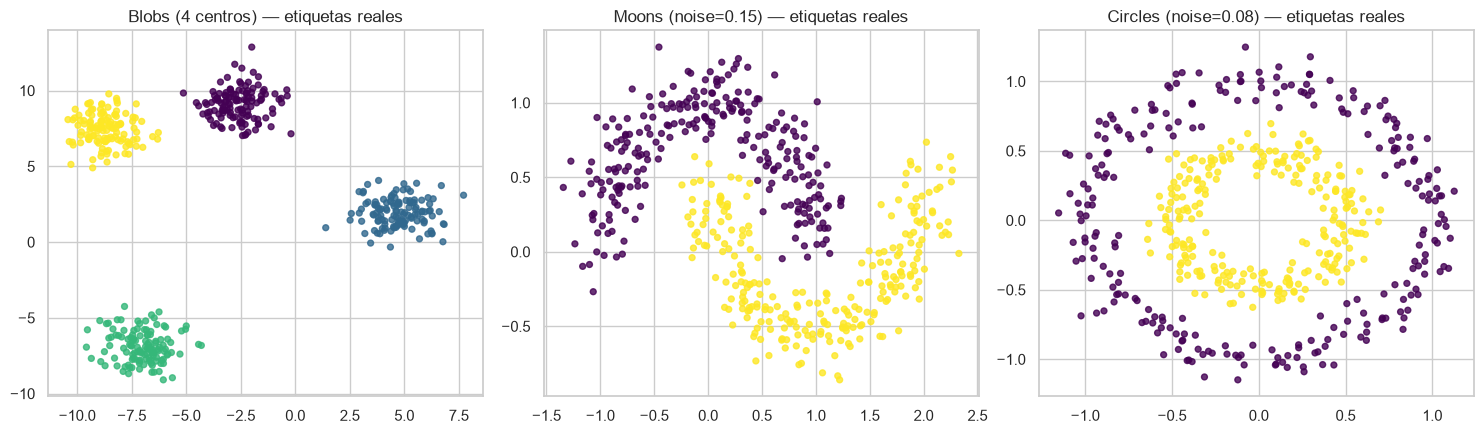

In [2]:
datasets = {
    "Blobs (4 centros)": (*make_blobs(n_samples=500, centers=4, cluster_std=1.0, random_state=RS), 4),
    "Moons (noise=0.15)": (*make_moons(n_samples=500, noise=0.15, random_state=RS), 2),
    "Circles (noise=0.08)": (*make_circles(n_samples=500, noise=0.08, factor=0.5, random_state=RS), 2),
}
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (n, (X, y, k)) in zip(axes, datasets.items()):
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="viridis", s=18, alpha=0.8); ax.set_title(f"{n} — etiquetas reales")
plt.tight_layout(); plt.show()

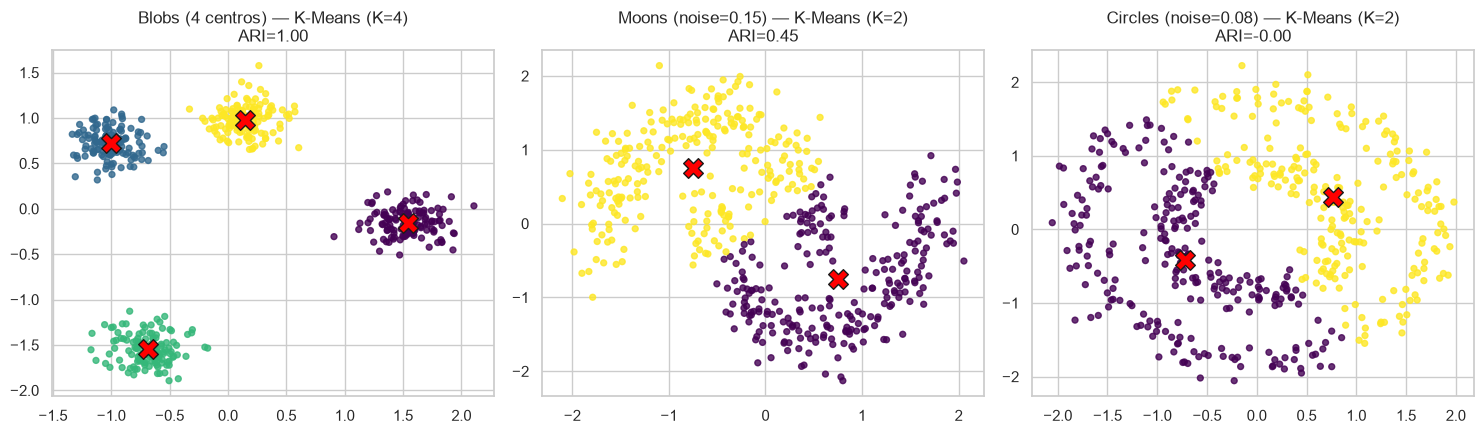

,ARI,Silhouette
Blobs (4 centros),1.000,0.798
Moons (noise=0.15),0.445,0.479
Circles (noise=0.08),-0.002,0.353


In [3]:
res = {}
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (n, (X, y, k)) in zip(axes, datasets.items()):
    Xs = StandardScaler().fit_transform(X)
    km = KMeans(n_clusters=k, n_init=10, random_state=RS); lab = km.fit_predict(Xs)
    res[n] = {"ARI": adjusted_rand_score(y, lab), "Silhouette": silhouette_score(Xs, lab)}
    ax.scatter(Xs[:, 0], Xs[:, 1], c=lab, cmap="viridis", s=18, alpha=0.8)
    ax.scatter(*km.cluster_centers_.T, c="red", marker="X", s=200, edgecolors="k")
    ax.set_title(f"{n} — K-Means (K={k})\nARI={res[n]['ARI']:.2f}")
plt.tight_layout(); plt.show(); display(pd.DataFrame(res).T.round(3))

**Respuestas 1.1** — K-Means funciona bien en **blobs** (grupos compactos, esféricos y separados; ARI = 1). Falla en **circles** (ARI ≈ 0) y rinde mal en **moons** (ARI ≈ 0.45): K-Means asigna cada punto al centroide más cercano, así que solo produce regiones **convexas** separadas por **fronteras lineales**; no puede separar un anillo que rodea a otro grupo ni dos medias lunas entrelazadas. Para esas formas hace falta DBSCAN, jerárquico *single linkage* o clustering espectral.

## Ejercicio 1.2 — K-Means manual paso a paso

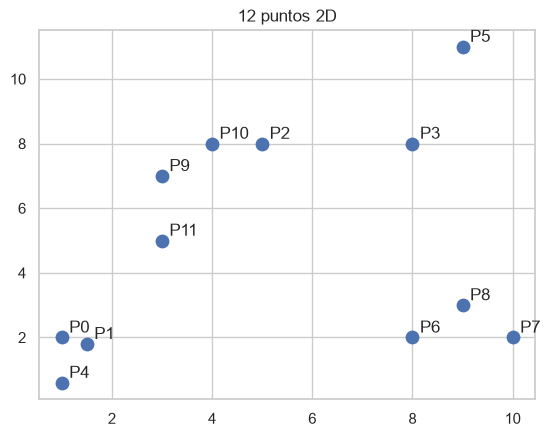

In [4]:
X = np.array([[1,2],[1.5,1.8],[5,8],[8,8],[1,0.6],[9,11],[8,2],[10,2],[9,3],[3,7],[4,8],[3,5]])
plt.scatter(X[:, 0], X[:, 1], s=80)
for i, (a, b) in enumerate(X): plt.annotate(f"P{i}", (a + 0.15, b + 0.15))
plt.title("12 puntos 2D"); plt.show()

===== Iteración 1 =====
Centroides de entrada:
[[1. 1.]
 [9. 9.]]


,d(C0),d(C1),cluster
0,1.00,10.63,0
1,0.94,10.40,0
2,8.06,4.12,1
3,9.90,1.41,1
4,0.40,11.60,0
5,12.81,2.00,1
6,7.07,7.07,0
7,9.06,7.07,1
8,8.25,6.00,1
9,6.32,6.32,0


Nuevos centroides (media de cada cluster):
 [[2.917 3.067]
 [7.5   6.667]] 

===== Iteración 2 =====
Centroides de entrada:
[[2.917 3.067]
 [7.5   6.667]]


,d(C0),d(C1),cluster
0,2.19,8.00,0
1,1.90,7.73,0
2,5.36,2.83,1
3,7.08,1.42,1
4,3.12,8.89,0
5,10.00,4.59,1
6,5.19,4.69,1
7,7.16,5.29,1
8,6.08,3.96,1
9,3.93,4.51,0


Nuevos centroides (media de cada cluster):
 [[1.9   3.28 ]
 [7.571 6.   ]] 

===== Iteración 3 =====
Centroides de entrada:
[[1.9   3.28 ]
 [7.571 6.   ]]


,d(C0),d(C1),cluster
0,1.56,7.69,0
1,1.53,7.38,0
2,5.65,3.26,1
3,7.71,2.05,1
4,2.83,8.51,0
5,10.49,5.20,1
6,6.23,4.02,1
7,8.20,4.68,1
8,7.11,3.32,1
9,3.88,4.68,0


Nuevos centroides (media de cada cluster):
 [[1.9   3.28 ]
 [7.571 6.   ]] 



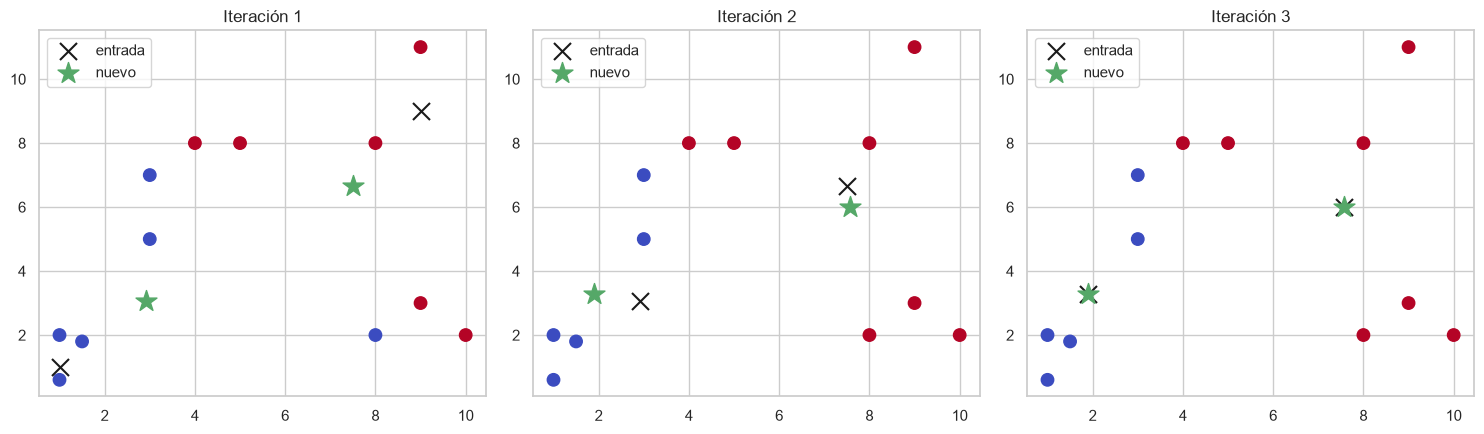

In [5]:
def kmeans_manual(X, centroides, iteraciones=3, verbose=True, dibujar=True):
    cent = np.array(centroides, dtype=float)
    fig, axes = plt.subplots(1, iteraciones, figsize=(5 * iteraciones, 4.5)) if dibujar else (None, [None] * iteraciones)
    for it in range(1, iteraciones + 1):
        dist = np.linalg.norm(X[:, None, :] - cent[None, :, :], axis=2)      # (n_puntos, K)
        lab = dist.argmin(axis=1)
        nuevo = np.array([X[lab == k].mean(axis=0) if np.any(lab == k) else cent[k] for k in range(len(cent))])
        if verbose:
            print(f"===== Iteración {it} =====\nCentroides de entrada:\n{cent.round(3)}")
            display(pd.DataFrame(dist.round(2), columns=[f"d(C{k})" for k in range(len(cent))]).assign(cluster=lab))
            print("Nuevos centroides (media de cada cluster):\n", nuevo.round(3), "\n")
        if dibujar:
            ax = axes[it - 1]; ax.scatter(*X.T, c=lab, cmap="coolwarm", s=80)
            ax.scatter(*cent.T, c="k", marker="x", s=150, label="entrada"); ax.scatter(*nuevo.T, c="g", marker="*", s=250, label="nuevo")
            ax.set_title(f"Iteración {it}"); ax.legend()
        cent = nuevo
    if dibujar: plt.tight_layout(); plt.show()
    return cent, lab

cent_final, lab_manual = kmeans_manual(X, [[1, 1], [9, 9]], iteraciones=3)

In [6]:
km = KMeans(n_clusters=2, n_init=10, random_state=RS).fit(X)
print("Centroides sklearn:\n", km.cluster_centers_.round(3)); print("Centroides manual:\n", cent_final.round(3))
print("Etiquetas manual :", lab_manual); print("Etiquetas sklearn:", km.labels_)
print("ARI manual vs sklearn:", adjusted_rand_score(lab_manual, km.labels_))

# ¿Cambian los clusters con otros centroides iniciales?
for ini in ([[1, 1], [9, 9]], [[1, 2], [1.5, 1.8]], [[8, 8], [9, 11]], [[3, 5], [4, 8]]):
    _, lab = kmeans_manual(X, ini, iteraciones=10, verbose=False, dibujar=False)
    print(f"Inicio {ini} -> tamaños de cluster: {np.bincount(lab)}  | ARI vs sklearn: {adjusted_rand_score(lab, km.labels_):.2f}")

Centroides sklearn:
 [[1.625 2.35 ]
 [7.    6.125]]
Centroides manual:
 [[1.9   3.28 ]
 [7.571 6.   ]]
Etiquetas manual : [0 0 1 1 0 1 1 1 1 0 1 0]
Etiquetas sklearn: [0 0 1 1 0 1 1 1 1 1 1 0]
ARI manual vs sklearn: 0.6672777268560953
Inicio [[1, 1], [9, 9]] -> tamaños de cluster: [5 7]  | ARI vs sklearn: 0.67
Inicio [[1, 2], [1.5, 1.8]] -> tamaños de cluster: [5 7]  | ARI vs sklearn: 0.67
Inicio [[8, 8], [9, 11]] -> tamaños de cluster: [7 5]  | ARI vs sklearn: 0.18
Inicio [[3, 5], [4, 8]] -> tamaños de cluster: [7 5]  | ARI vs sklearn: 0.18


**Respuesta 1.2** — En la ejecución de referencia, con centroides iniciales (1,1) y (9,9) el K-Means manual tras 3 iteraciones difiere de `sklearn` en **un solo punto** (ARI ≈ 0.67): aún no había convergido por completo (más iteraciones lo llevan al mismo resultado que `sklearn`). Además, **sí depende de la inicialización**: partiendo de centroides como (8,8)/(9,11) o (3,5)/(4,8) el algoritmo converge a **otro agrupamiento** (ARI ≈ 0.18 frente a `sklearn`), es decir, a un mínimo local distinto. Por eso `sklearn` usa `k-means++` y varias inicializaciones (`n_init`) y se queda con la de menor inercia.

## Ejercicio 1.3 — Importancia de la estandarización

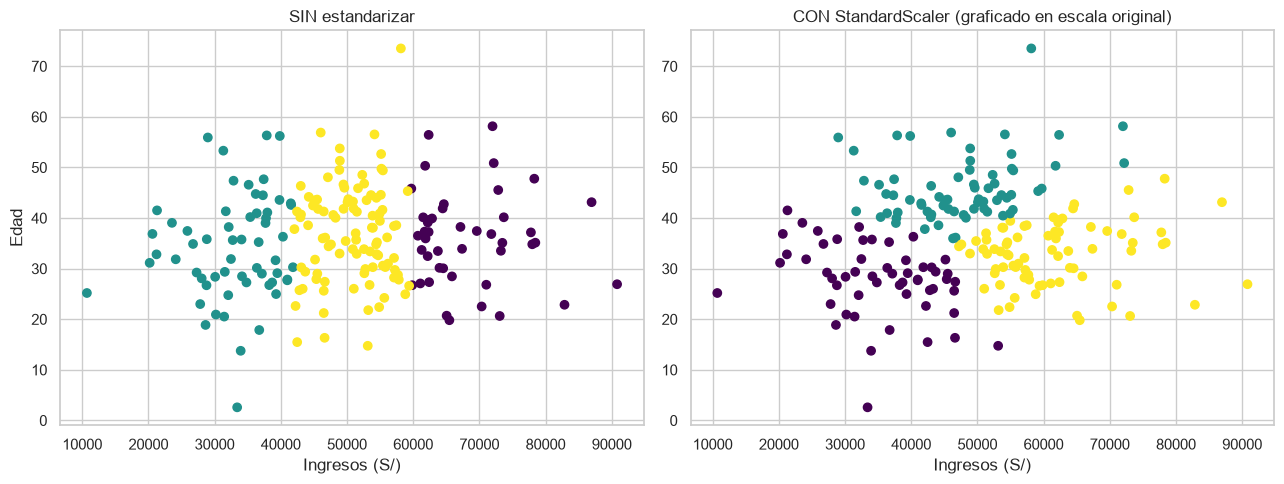

Silhouette sin estandarizar (en espacio original):  0.544
Silhouette con estandarizar (en espacio estandarizado): 0.376
Silhouette de AMBOS agrupamientos medidos en el espacio estandarizado -> sin: 0.232 | con: 0.376


In [7]:
np.random.seed(42)
ingresos = np.random.normal(50000, 15000, 200); edad = np.random.normal(35, 10, 200)
X = np.column_stack([ingresos, edad]); Xs = StandardScaler().fit_transform(X)

lab_raw = KMeans(3, n_init=10, random_state=RS).fit_predict(X)
lab_std = KMeans(3, n_init=10, random_state=RS).fit_predict(Xs)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(X[:, 0], X[:, 1], c=lab_raw, cmap="viridis"); axes[0].set_title("SIN estandarizar"); axes[0].set_xlabel("Ingresos (S/)"); axes[0].set_ylabel("Edad")
axes[1].scatter(X[:, 0], X[:, 1], c=lab_std, cmap="viridis"); axes[1].set_title("CON StandardScaler (graficado en escala original)"); axes[1].set_xlabel("Ingresos (S/)")
plt.tight_layout(); plt.show()
print(f"Silhouette sin estandarizar (en espacio original):  {silhouette_score(X, lab_raw):.3f}")
print(f"Silhouette con estandarizar (en espacio estandarizado): {silhouette_score(Xs, lab_std):.3f}")
print(f"Silhouette de AMBOS agrupamientos medidos en el espacio estandarizado -> sin: {silhouette_score(Xs, lab_raw):.3f} | con: {silhouette_score(Xs, lab_std):.3f}")

**Respuesta 1.3** — Sin estandarizar, la distancia euclidiana está dominada por `ingresos` (decenas de miles) frente a `edad` (decenas): los clusters resultan **franjas verticales que dependen casi solo del ingreso**, ignorando la edad. Con `StandardScaler` ambas variables pesan igual y los grupos reflejan las dos dimensiones. Ojo con comparar silhouettes en espacios distintos: la tercera línea las mide en el **mismo espacio estandarizado**, que es la comparación justa. El resultado más razonable es el estandarizado, porque ninguna variable debería dominar solo por sus unidades.

---
# Nivel 2: Intermedio
## Ejercicio 2.1 — Selección de K con Iris

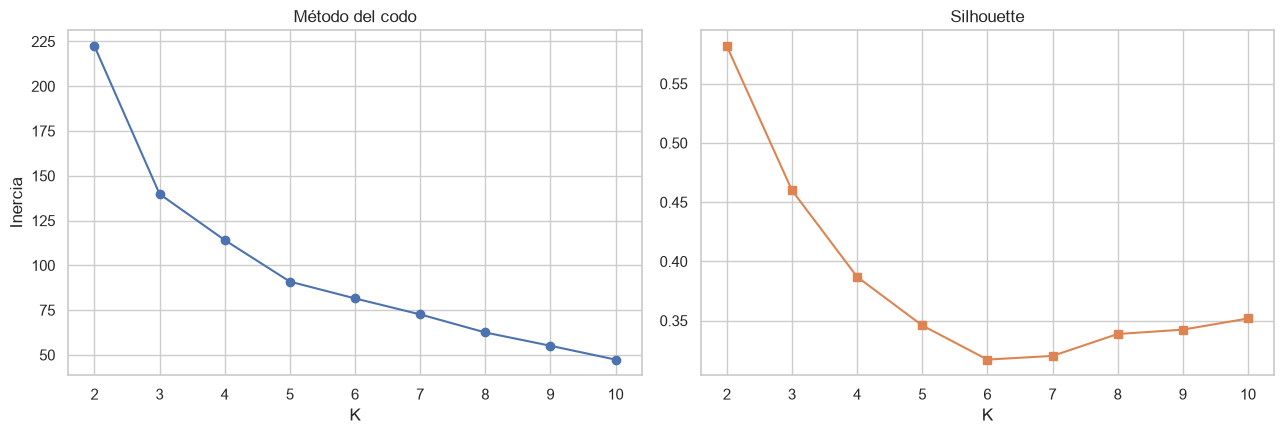

 K  Inercia  Silhouette
 2 222.3617      0.5818
 3 139.8205      0.4599
 4 114.0925      0.3869
 5  90.9275      0.3459
 6  81.5444      0.3171
 7  72.6311      0.3202
 8  62.5406      0.3387
 9  55.1195      0.3424
10  47.3910      0.3518
K con mejor silhouette: 2


In [8]:
iris = load_iris(); Xi = StandardScaler().fit_transform(iris.data); yi = iris.target
Ks = range(2, 11); inercia, sil = [], []
for k in Ks:
    km = KMeans(k, n_init=10, random_state=RS).fit(Xi); inercia.append(km.inertia_); sil.append(silhouette_score(Xi, km.labels_))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(Ks, inercia, "o-"); axes[0].set_title("Método del codo"); axes[0].set_xlabel("K"); axes[0].set_ylabel("Inercia")
axes[1].plot(Ks, sil, "s-", color="C1"); axes[1].set_title("Silhouette"); axes[1].set_xlabel("K"); plt.tight_layout(); plt.show()
print(pd.DataFrame({"K": list(Ks), "Inercia": inercia, "Silhouette": sil}).round(4).to_string(index=False))
print("K con mejor silhouette:", list(Ks)[int(np.argmax(sil))])

,Silhouette,ARI,NMI
K=2,0.5818,0.5681,0.7337
K=3,0.4599,0.6201,0.6595


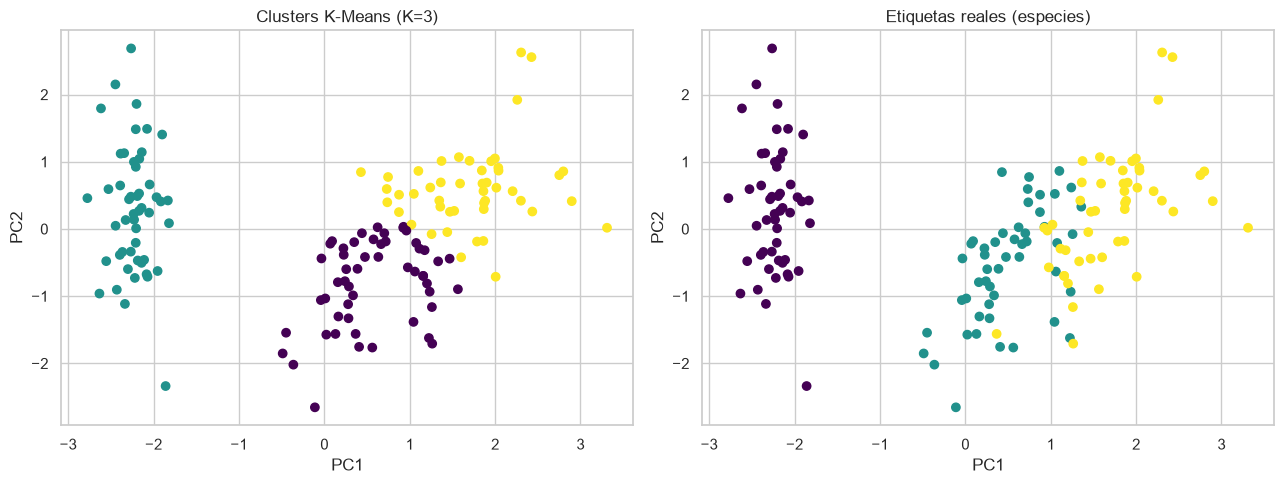

cluster   0   1   2
especie            
0         0  50   0
1        39   0  11
2        14   0  36


In [9]:
# El silhouette tiende a favorecer K=2 en Iris (dos especies se solapan); el codo y el conocimiento del dominio sugieren K=3.
res = {}
for k in [2, 3]:
    lab = KMeans(k, n_init=10, random_state=RS).fit_predict(Xi)
    res[f"K={k}"] = {"Silhouette": silhouette_score(Xi, lab), "ARI": adjusted_rand_score(yi, lab), "NMI": normalized_mutual_info_score(yi, lab)}
display(pd.DataFrame(res).T.round(4))

lab3 = KMeans(3, n_init=10, random_state=RS).fit_predict(Xi); Z = PCA(2, random_state=RS).fit_transform(Xi)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(Z[:, 0], Z[:, 1], c=lab3, cmap="viridis"); axes[0].set_title("Clusters K-Means (K=3)")
axes[1].scatter(Z[:, 0], Z[:, 1], c=yi, cmap="viridis"); axes[1].set_title("Etiquetas reales (especies)")
for ax in axes: ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
plt.tight_layout(); plt.show(); print(pd.crosstab(yi, lab3, rownames=["especie"], colnames=["cluster"]))

**Respuesta 2.1** — El silhouette suele ser máximo en **K=2** (setosa está muy separada; versicolor y virginica se solapan), mientras que el codo no es tajante y K=3 es razonable. Con **K=3** el clustering recupera bien las especies: setosa perfectamente, y versicolor/virginica con algunos puntos intercambiados (ARI ≈ 0.62, NMI ≈ 0.66). Es decir, **encontró aproximadamente las 3 especies**, sin usar las etiquetas, con confusión entre las dos solapadas.

## Ejercicio 2.2 — DBSCAN: efecto de eps y min_samples

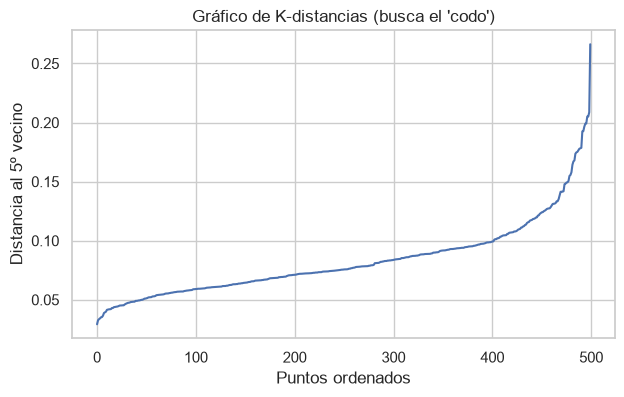

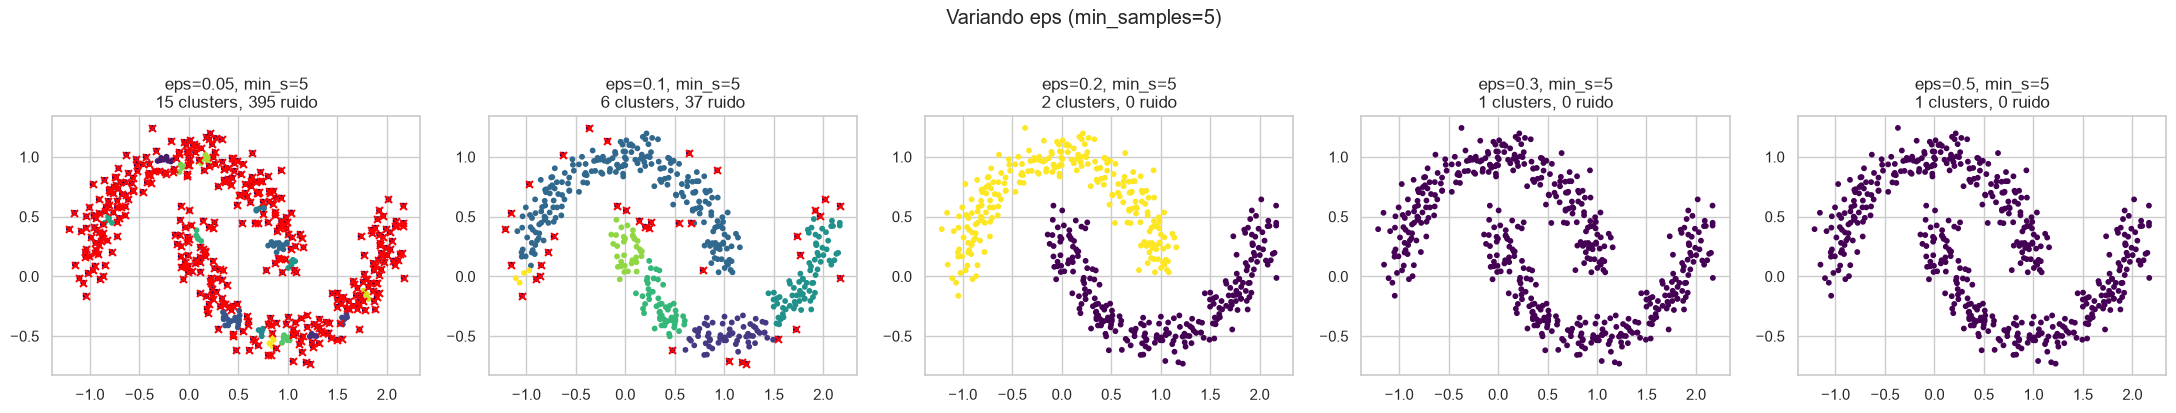

,eps,min_samples,clusters,ruido,silhouette,ARI
0,0.05,5,15,395,0.737,0.007
1,0.10,5,6,37,0.199,0.530
2,0.20,5,2,0,0.327,1.000
3,0.30,5,1,0,NaN,0.000
4,0.50,5,1,0,NaN,0.000


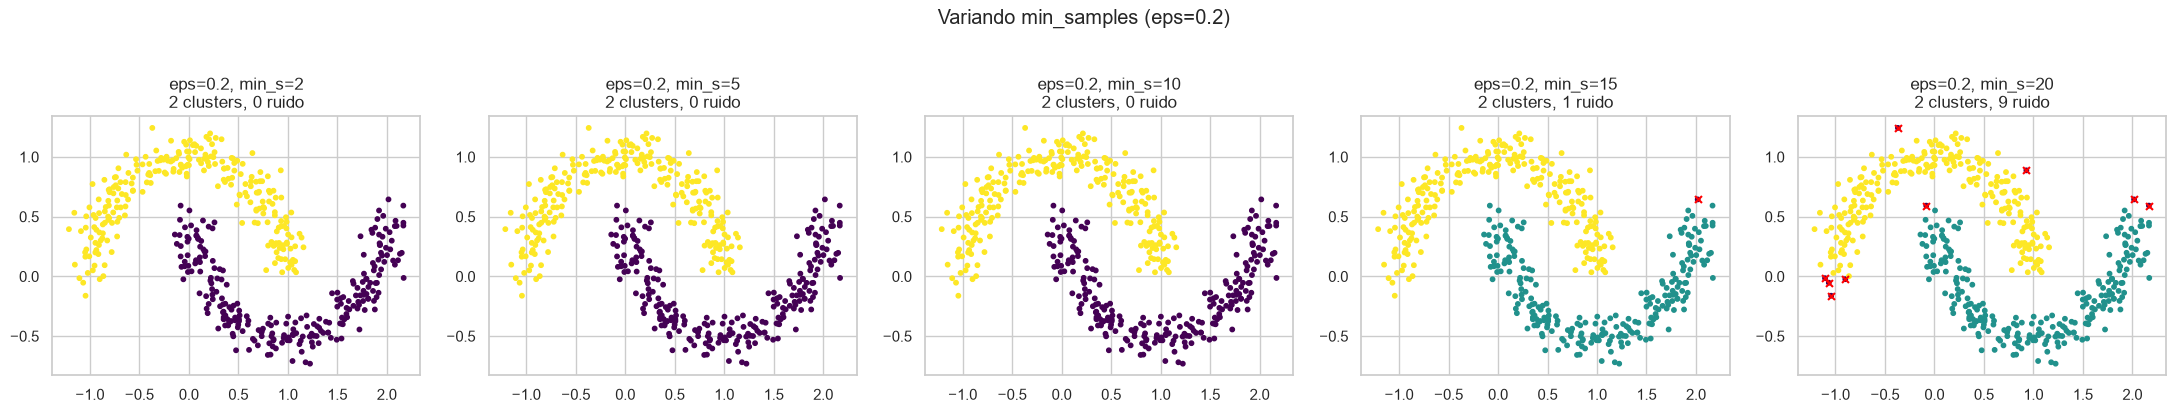

,eps,min_samples,clusters,ruido,silhouette,ARI
0,0.2,2,2,0,0.327,1.000
1,0.2,5,2,0,0.327,1.000
2,0.2,10,2,0,0.327,1.000
3,0.2,15,2,1,0.328,0.996
4,0.2,20,2,9,0.331,0.964


In [10]:
Xm, ym = make_moons(n_samples=500, noise=0.1, random_state=RS)
k = 5; d, _ = NearestNeighbors(n_neighbors=k).fit(Xm).kneighbors(Xm); kd = np.sort(d[:, -1])
plt.figure(figsize=(7, 4)); plt.plot(kd); plt.xlabel("Puntos ordenados"); plt.ylabel(f"Distancia al {k}º vecino"); plt.title("Gráfico de K-distancias (busca el 'codo')"); plt.grid(True); plt.show()

def evaluar(eps, ms):
    lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(Xm)
    ncl = len(set(lab)) - (1 if -1 in lab else 0); ruido = int((lab == -1).sum()); mask = lab != -1
    sil = silhouette_score(Xm[mask], lab[mask]) if ncl >= 2 and mask.sum() > ncl else np.nan
    return lab, {"eps": eps, "min_samples": ms, "clusters": ncl, "ruido": ruido, "silhouette": sil, "ARI": adjusted_rand_score(ym, lab)}

def cuadricula(configs, titulo):
    fig, axes = plt.subplots(1, 5, figsize=(22, 4)); filas = []
    for ax, (eps, ms) in zip(axes, configs):
        lab, r = evaluar(eps, ms); filas.append(r)
        ax.scatter(Xm[:, 0], Xm[:, 1], c=lab, cmap="viridis", s=10); ax.scatter(*Xm[lab == -1].T, c="red", marker="x", s=25)
        ax.set_title(f"eps={eps}, min_s={ms}\n{r['clusters']} clusters, {r['ruido']} ruido")
    plt.suptitle(titulo, y=1.03); plt.tight_layout(); plt.show(); return pd.DataFrame(filas)

t1 = cuadricula([(e, 5) for e in [0.05, 0.1, 0.2, 0.3, 0.5]], "Variando eps (min_samples=5)"); display(t1.round(3))
t2 = cuadricula([(0.2, m) for m in [2, 5, 10, 15, 20]], "Variando min_samples (eps=0.2)"); display(t2.round(3))

**Respuestas 2.2** — **`eps`** es el radio de vecindad: demasiado pequeño (0.05) → casi todo es ruido y muchos micro-clusters; demasiado grande (0.5) → las dos lunas se fusionan en un solo cluster. **`min_samples`** es la densidad mínima: valores bajos (2) crean muchos clusters pequeños y poco ruido; valores altos (15–20) etiquetan más puntos como ruido y pueden fragmentar. La mejor combinación (la que da 2 clusters con ARI ≈ 1 y poco ruido; en este dataset típicamente **eps ≈ 0.2, min_samples ≈ 5**) coincide con el codo del gráfico de K-distancias; verifica en la columna `ARI` de la tabla.

## Ejercicio 2.3 — Clustering jerárquico: comparación de linkages

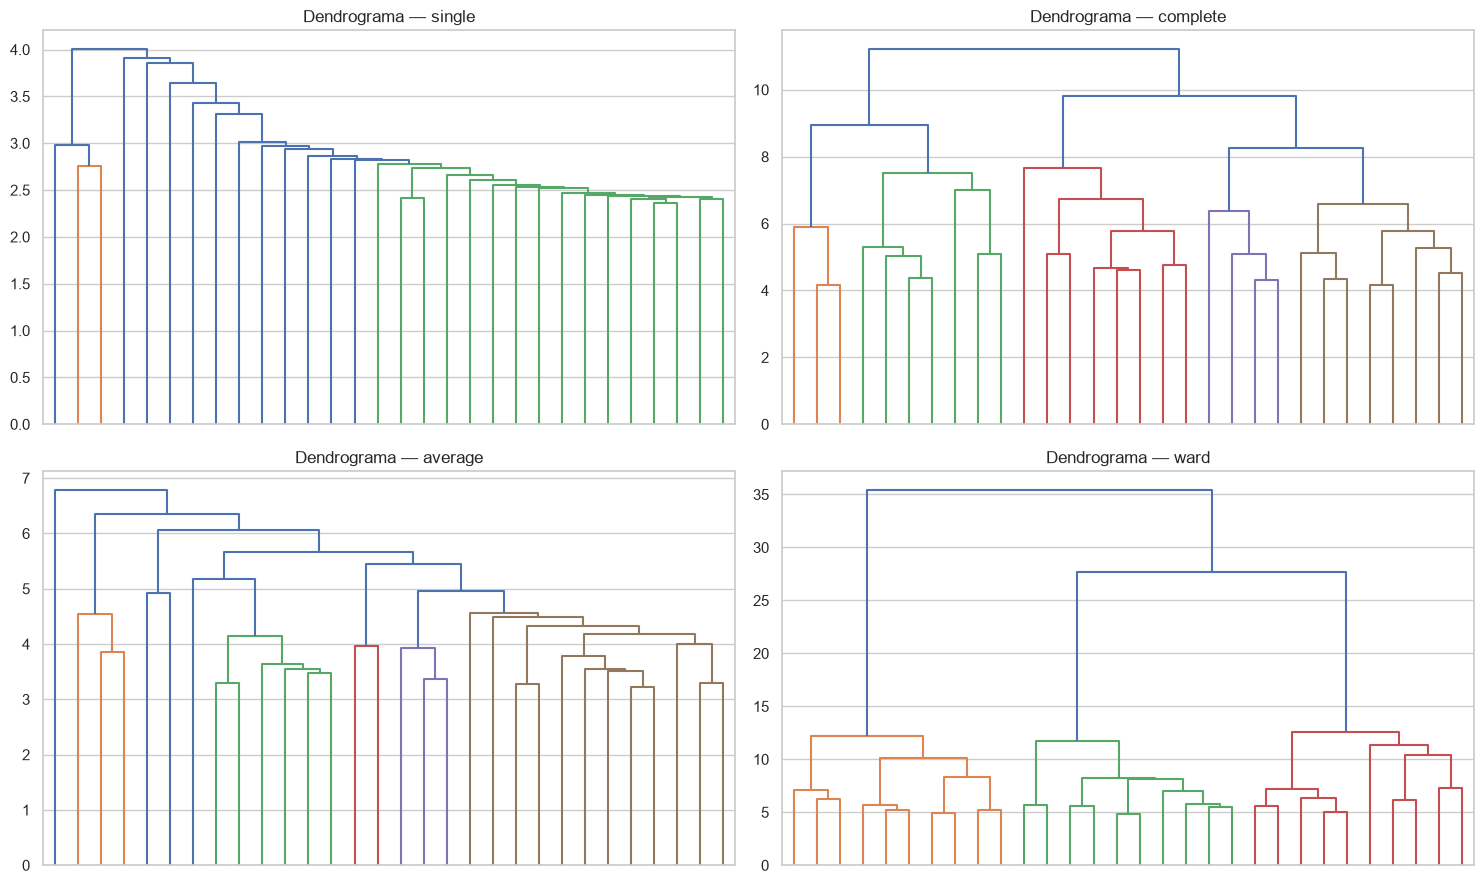

In [11]:
wine = load_wine(); Xw = StandardScaler().fit_transform(wine.data); yw = wine.target
linkages = ["single", "complete", "average", "ward"]
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
for ax, l in zip(axes.ravel(), linkages):
    dendrogram(linkage(Xw, method=l), truncate_mode="lastp", p=30, ax=ax, no_labels=True); ax.set_title(f"Dendrograma — {l}")
plt.tight_layout(); plt.show()

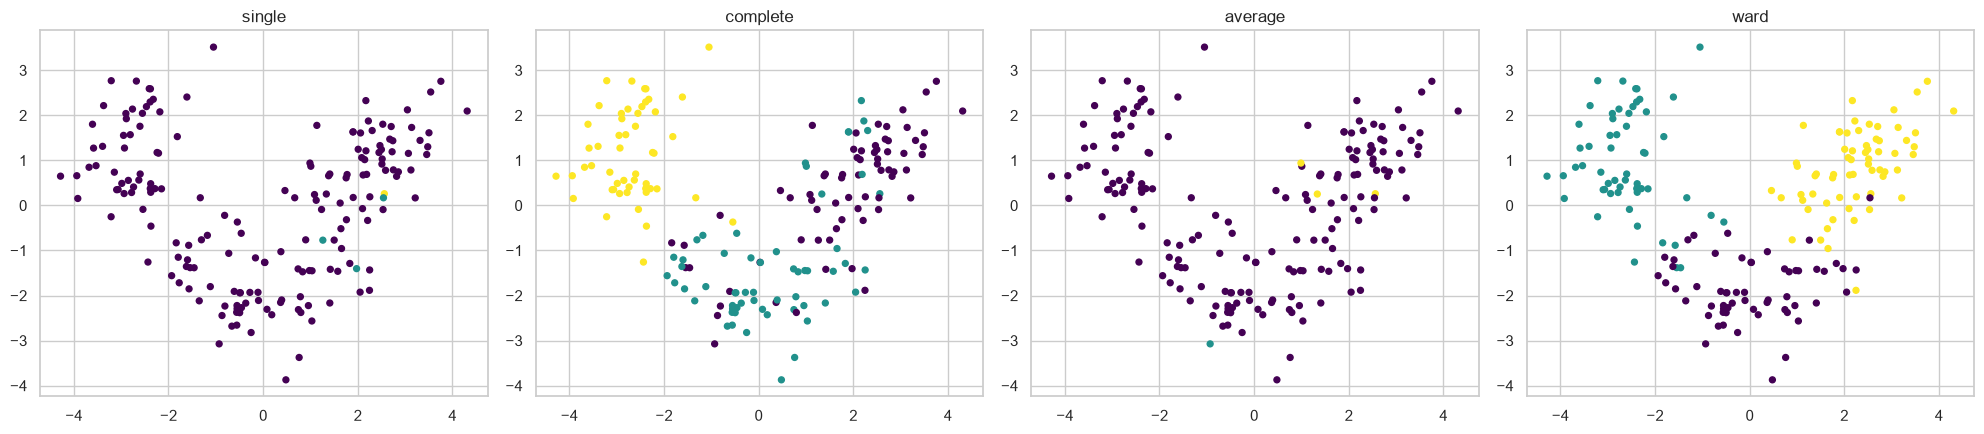

,linkage,Silhouette,ARI,tamaños
0,single,0.1827,-0.0068,"[174, 3, 1]"
1,complete,0.2038,0.5771,"[69, 58, 51]"
2,average,0.1575,-0.0054,"[174, 1, 3]"
3,ward,0.2774,0.7899,"[58, 56, 64]"


In [12]:
Z2 = PCA(2, random_state=RS).fit_transform(Xw); filas = []
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, l in zip(axes, linkages):
    lab = AgglomerativeClustering(n_clusters=3, linkage=l).fit_predict(Xw)
    filas.append({"linkage": l, "Silhouette": silhouette_score(Xw, lab), "ARI": adjusted_rand_score(yw, lab), "tamaños": np.bincount(lab).tolist()})
    ax.scatter(Z2[:, 0], Z2[:, 1], c=lab, cmap="viridis", s=18); ax.set_title(f"{l}")
plt.tight_layout(); plt.show(); display(pd.DataFrame(filas).round(4))

**Respuestas 2.3** — **Ward** suele dar los mejores clusters en Wine (ARI ≈ 0.79, tamaños equilibrados). *Single* sufre el **efecto cadena** (un cluster enorme y otros de 1–2 puntos); *complete* y *average* quedan en medio y son sensibles a outliers/formas. **Ward es el predeterminado** porque minimiza el aumento de varianza intra-cluster en cada fusión (el mismo criterio que K-Means), produce clusters compactos y de tamaño similar, y es robusto frente al efecto cadena; requiere distancia euclidiana.

## Ejercicio 2.4 — Serialización y carga de modelos

In [13]:
Xw_raw, yw = wine.data, wine.target
pipe = make_pipeline(StandardScaler(), RandomForestClassifier(n_estimators=100, random_state=RS))
cv = StratifiedKFold(5, shuffle=True, random_state=RS)
sc = cross_val_score(pipe, Xw_raw, yw, cv=cv); print(f"Accuracy CV: {sc.mean():.4f} ± {sc.std():.4f}")
pipe.fit(Xw_raw, yw); pred_original = pipe.predict(Xw_raw)
joblib.dump(pipe, "models/wine_pipeline.joblib"); print("Guardado con joblib")

Accuracy CV: 0.9775 ± 0.0213
Guardado con joblib


In [14]:
# --- Simulación de un 'script nuevo': borramos todo y cargamos desde disco ---
del pipe
import joblib; import numpy as np
from sklearn.datasets import load_wine
pipe_cargado = joblib.load("models/wine_pipeline.joblib")
pred_cargado = pipe_cargado.predict(load_wine().data)
print("¿Predicciones idénticas?", np.array_equal(pred_original, pred_cargado))
print("Pasos del pipeline cargado:", [n for n, _ in pipe_cargado.steps])

¿Predicciones idénticas? True
Pasos del pipeline cargado: ['standardscaler', 'randomforestclassifier']


In [15]:
with open("models/wine_pipeline.pkl", "wb") as f: pickle.dump(pipe_cargado, f)
for p in ["models/wine_pipeline.joblib", "models/wine_pipeline.pkl"]: print(f"{p}: {os.path.getsize(p) / 1024:.1f} KB")
with open("models/wine_pipeline.pkl", "rb") as f: print("pickle idéntico:", np.array_equal(pickle.load(f).predict(load_wine().data), pred_original))

models/wine_pipeline.joblib: 224.0 KB
models/wine_pipeline.pkl: 214.8 KB
pickle idéntico: True


**Respuesta 2.4** — Hay que guardar el **pipeline completo** porque el modelo fue entrenado con datos *ya escalados*: si se guarda solo el `RandomForest`, en producción habría que reconstruir a mano el `StandardScaler` con **exactamente la media y desviación del entrenamiento**; si se olvida o se reajusta con datos nuevos, las entradas quedan en otra escala y las predicciones son incorrectas (sin error visible). El pipeline encapsula preprocesado + modelo en un solo objeto reproducible. **joblib vs pickle:** el resultado es equivalente; joblib es más eficiente con arrays NumPy grandes (y admite compresión), con tamaños de archivo similares en modelos pequeños. 

---
# Nivel 3: Avanzado
## Ejercicio 3.1 — Comparación justa de algoritmos de clustering
Iris, Wine y Digits (solo clases 0, 1, 2). `DBSCAN` no recibe K: se elige `eps` sin usar etiquetas (maximizando el silhouette sobre una rejilla de cuantiles de distancias al 5º vecino).

In [16]:
def mejor_dbscan(X, ms=5):
    d, _ = NearestNeighbors(n_neighbors=ms).fit(X).kneighbors(X); kd = d[:, -1]; mejor = (-2, None)
    for q in np.linspace(0.5, 0.99, 25):
        lab = DBSCAN(eps=np.quantile(kd, q), min_samples=ms).fit_predict(X); mask = lab != -1; ncl = len(set(lab[mask]))
        if ncl >= 2 and mask.sum() > ncl:
            s = silhouette_score(X[mask], lab[mask])
            if s > mejor[0]: mejor = (s, lab)
    return mejor[1] if mejor[1] is not None else -np.ones(len(X), dtype=int)

def metricas_cluster(X, y, lab):
    mask = lab != -1; ncl = len(set(lab[mask]))
    interno = ncl >= 2 and mask.sum() > ncl
    return {"Silhouette": silhouette_score(X[mask], lab[mask]) if interno else np.nan,
            "Calinski-Harabasz": calinski_harabasz_score(X[mask], lab[mask]) if interno else np.nan,
            "Davies-Bouldin": davies_bouldin_score(X[mask], lab[mask]) if interno else np.nan,
            "ARI": adjusted_rand_score(y, lab), "NMI": normalized_mutual_info_score(y, lab), "% ruido": float((lab == -1).mean() * 100)}

data = {"Iris": (load_iris().data, load_iris().target), "Wine": (load_wine().data, load_wine().target),
        "Digits (0,1,2)": (load_digits(n_class=3).data, load_digits(n_class=3).target)}
filas = []
for dn, (Xr, y) in data.items():
    X = StandardScaler().fit_transform(Xr)
    algos = {"K-Means": KMeans(3, n_init=10, random_state=RS).fit_predict(X), "DBSCAN": mejor_dbscan(X),
             "Jerárquico (ward)": AgglomerativeClustering(3, linkage="ward").fit_predict(X),
             "GMM": GaussianMixture(3, n_init=5, random_state=RS).fit(X).predict(X)}
    for an, lab in algos.items(): filas.append({"Dataset": dn, "Algoritmo": an, **metricas_cluster(X, y, lab)})
tabla = pd.DataFrame(filas).set_index(["Dataset", "Algoritmo"]); display(tabla.round(3))

Silhouette  Calinski-Harabasz  \
Dataset        Algoritmo                                          
Iris           K-Means                 0.460            241.904   
               DBSCAN                  0.657            340.712   
               Jerárquico (ward)       0.447            222.719   
               GMM                     0.374            187.774   
Wine           K-Means                 0.285             70.940   
               DBSCAN                  0.342             71.253   
               Jerárquico (ward)       0.277             67.647   
               GMM                     0.284             70.688   
Digits (0,1,2) K-Means                 0.255            126.216   
               DBSCAN                  0.339            126.707   
               Jerárquico (ward)       0.255            125.432   
               GMM                     0.248            122.835   

                                  Davies-Bouldin    ARI    NMI  % ruido  
Dataset        Algoritmo                                                 
Iris           K-Means                     0.834  0.620  0.659    0.000  
               DBSCAN                      0.494  0.444  0.512   24.000  
               Jerárquico (ward)           0.803  0.615  0.675    0.000  
               GMM                         1.081  0.904  0.900    0.000  
Wine           K-Means                     1.389  0.897  0.876    0.000  
               DBSCAN                      1.159  0.382  0.468   27.528  
               Jerárquico (ward)           1.419  0.790  0.786    0.000  
               GMM                         1.394  0.880  0.861    0.000  
Digits (0,1,2) K-Means                     1.783  0.768  0.747    0.000  
               DBSCAN                      1.284  0.527  0.624   31.844  
               Jerárquico (ward)           1.785  0.809  0.800    0.000  
               GMM                         1.804  0.744  0.738    0.000

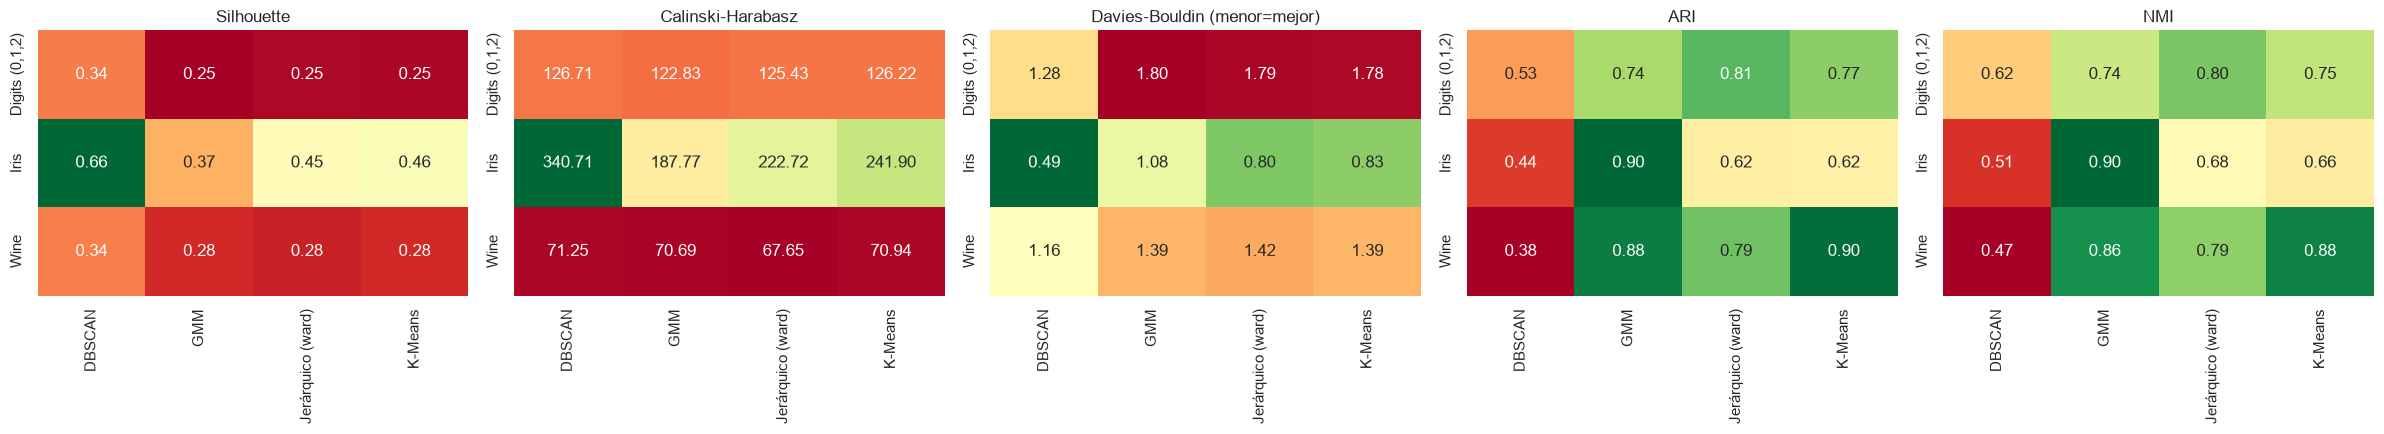

Mejor algoritmo por dataset según ARI:
Dataset
Digits (0,1,2)    Jerárquico (ward)
Iris                            GMM
Wine                        K-Means
dtype: str

ARI promedio por algoritmo:
Algoritmo
DBSCAN               0.451
GMM                  0.843
Jerárquico (ward)    0.738
K-Means              0.762
dtype: float64


In [17]:
metr = ["Silhouette", "Calinski-Harabasz", "Davies-Bouldin", "ARI", "NMI"]
fig, axes = plt.subplots(1, 5, figsize=(24, 4.5))
for ax, m in zip(axes, metr):
    sns.heatmap(tabla[m].unstack(), annot=True, fmt=".2f", cmap="RdYlGn_r" if m == "Davies-Bouldin" else "RdYlGn", ax=ax, cbar=False)
    ax.set_title(m + (" (menor=mejor)" if m == "Davies-Bouldin" else "")); ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout(); plt.show()
print("Mejor algoritmo por dataset según ARI:"); print(tabla["ARI"].unstack().idxmax(axis=1))
print("\nARI promedio por algoritmo:"); print(tabla["ARI"].unstack().mean().round(3))

**Respuestas 3.1**

- **¿Hay un algoritmo mejor en todos los datasets?** No. En la ejecución de referencia, por ARI ganó **GMM en Iris, K-Means en Wine y ward en Digits (0,1,2)**. DBSCAN depende mucho de `eps` y descarta puntos como ruido (≈ 24 % en Iris), por lo que su silhouette sale alto pero su ARI es bajo.
- **¿Coinciden métricas internas y externas?** Solo parcialmente. Las internas (Silhouette, Calinski-Harabasz, Davies-Bouldin) premian clusters compactos y separados y **no conocen las etiquetas**; las externas (ARI/NMI) miden acuerdo con las clases reales. Un algoritmo puede tener buen silhouette y bajo ARI (p. ej. DBSCAN en Iris: silhouette 0.66 pero ARI 0.44, porque el silhouette se calcula excluyendo el ruido y con 2 clusters) y viceversa. Además, Calinski-Harabasz y Davies-Bouldin favorecen a K-Means por diseño (clusters esféricos).
- **Primera opción:** **K-Means** (o **GMM** si se esperan clusters elípticos / se quiere asignación probabilística): rápido, estable y se evalúa fácil con silhouette; **ward** es una excelente alternativa si hay pocos datos y se quiere el dendrograma. DBSCAN se usa cuando se sospechan formas arbitrarias y ruido.

## Ejercicio 3.2 — API REST con Flask
### 1. Entrenar y guardar el pipeline

In [18]:
wine = load_wine(); Xdf = pd.DataFrame(wine.data, columns=wine.feature_names)
pipe_api = make_pipeline(StandardScaler(), RandomForestClassifier(n_estimators=100, random_state=RS)).fit(Xdf, wine.target)
joblib.dump(pipe_api, "models/wine_pipeline.joblib")
print("Features esperadas:", len(wine.feature_names)); print("Ejemplo (muestra 0):", Xdf.iloc[0].round(3).tolist())

Features esperadas: 13
Ejemplo (muestra 0): [14.23, 1.71, 2.43, 15.6, 127.0, 2.8, 3.06, 0.28, 2.29, 5.64, 1.04, 3.92, 1065.0]


### 2. `app.py`

In [19]:
%%writefile app.py
from flask import Flask, request, jsonify
import joblib
import numpy as np
import pandas as pd

app = Flask(__name__)
MODEL_PATH = "models/wine_pipeline.joblib"
pipe = joblib.load(MODEL_PATH)
FEATURES = ["alcohol", "malic_acid", "ash", "alcalinity_of_ash", "magnesium", "total_phenols", "flavanoids",
            "nonflavanoid_phenols", "proanthocyanins", "color_intensity", "hue",
            "od280/od315_of_diluted_wines", "proline"]
CLASES = ["class_0", "class_1", "class_2"]


def error(msg, code=400):
    return jsonify({"error": msg}), code


@app.get("/health")
def health():
    return jsonify({"status": "ok", "model": "wine_pipeline", "n_features": len(FEATURES)})


@app.post("/predict")
def predict():
    data = request.get_json(silent=True)
    if not isinstance(data, dict) or "features" not in data:
        return error("El cuerpo debe ser JSON con la clave 'features' (lista de 13 valores o diccionario nombre->valor).")
    feats = data["features"]
    if isinstance(feats, dict):
        faltan = [f for f in FEATURES if f not in feats]
        if faltan:
            return error(f"Faltan features: {faltan}")
        valores = [feats[f] for f in FEATURES]
    elif isinstance(feats, list):
        if len(feats) != len(FEATURES):
            return error(f"Se esperaban {len(FEATURES)} valores, se recibieron {len(feats)}.")
        valores = feats
    else:
        return error("'features' debe ser una lista o un diccionario.")
    try:
        arr = np.array(valores, dtype=float)
    except (TypeError, ValueError):
        return error("Todos los valores deben ser numéricos.")
    if not np.all(np.isfinite(arr)):
        return error("Los valores no pueden ser NaN ni infinitos.")
    X = pd.DataFrame([arr], columns=FEATURES)
    proba = pipe.predict_proba(X)[0]
    idx = int(np.argmax(proba))
    return jsonify({"clase": idx, "nombre_clase": CLASES[idx],
                    "probabilidades": {CLASES[i]: round(float(p), 4) for i, p in enumerate(proba)}})


@app.errorhandler(404)
def not_found(e):
    return error("Ruta no encontrada.", 404)


@app.errorhandler(405)
def not_allowed(e):
    return error("Método no permitido.", 405)


@app.errorhandler(500)
def server_error(e):
    return error("Error interno del servidor.", 500)


if __name__ == "__main__":
    app.run(host="127.0.0.1", port=5000, debug=False)


Writing app.py


### 3. Probar la API localmente (servidor en segundo plano)

In [20]:
import requests
servidor = subprocess.Popen([sys.executable, "app.py"], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
for _ in range(30):                       # esperar a que el servidor arranque
    try: requests.get("http://127.0.0.1:5000/health", timeout=1); break
    except Exception: time.sleep(0.5)
URL = "http://127.0.0.1:5000"
print("GET /health ->", requests.get(f"{URL}/health").json())
muestra = Xdf.iloc[0].tolist()
r = requests.post(f"{URL}/predict", json={"features": muestra}); print("POST /predict (lista) ->", r.status_code, r.json(), "| real:", wine.target[0])
r = requests.post(f"{URL}/predict", json={"features": Xdf.iloc[100].to_dict()}); print("POST /predict (dict)  ->", r.status_code, r.json(), "| real:", wine.target[100])
print("\n--- Errores controlados ---")
print("Lista corta :", requests.post(f"{URL}/predict", json={"features": [1, 2, 3]}).json())
print("No numérico :", requests.post(f"{URL}/predict", json={"features": ["a"] * 13}).json())
print("Sin 'features':", requests.post(f"{URL}/predict", json={"x": 1}).json())
print("No es JSON  :", requests.post(f"{URL}/predict", data="hola").json())
print("GET /predict:", requests.get(f"{URL}/predict").status_code)

GET /health -> {'model': 'wine_pipeline', 'n_features': 13, 'status': 'ok'}
POST /predict (lista) -> 200 {'clase': 0, 'nombre_clase': 'class_0', 'probabilidades': {'class_0': 0.99, 'class_1': 0.01, 'class_2': 0.0}} | real: 0
POST /predict (dict)  -> 200 {'clase': 1, 'nombre_clase': 'class_1', 'probabilidades': {'class_0': 0.01, 'class_1': 0.99, 'class_2': 0.0}} | real: 1

--- Errores controlados ---
Lista corta : {'error': 'Se esperaban 13 valores, se recibieron 3.'}
No numérico : {'error': 'Todos los valores deben ser numéricos.'}
Sin 'features': {'error': "El cuerpo debe ser JSON con la clave 'features' (lista de 13 valores o diccionario nombre->valor)."}
No es JSON  : {'error': "El cuerpo debe ser JSON con la clave 'features' (lista de 13 valores o diccionario nombre->valor)."}
GET /predict: 405


### 4. Bonus: `test_api.py` — cliente con 10 muestras

In [21]:
%%writefile test_api.py
import requests
from sklearn.datasets import load_wine

URL = "http://127.0.0.1:5000"
wine = load_wine()
idx = [0, 10, 30, 59, 65, 70, 100, 120, 150, 170]  # 10 muestras de las 3 clases
aciertos = 0
for i in idx:
    r = requests.post(f"{URL}/predict", json={"features": wine.data[i].tolist()})
    out = r.json()
    ok = out["clase"] == int(wine.target[i])
    aciertos += ok
    print(f"Muestra {i:3d} | real={wine.target[i]} | pred={out['clase']} | {'OK' if ok else 'ERROR'} | {out['probabilidades']}")
print(f"\nAciertos: {aciertos}/{len(idx)}")


Writing test_api.py


In [22]:
resultado = subprocess.run([sys.executable, "test_api.py"], capture_output=True, text=True); print(resultado.stdout or resultado.stderr)
servidor.terminate(); servidor.wait(); print("Servidor detenido.")

Muestra   0 | real=0 | pred=0 | OK | {'class_0': 0.99, 'class_1': 0.01, 'class_2': 0.0}
Muestra  10 | real=0 | pred=0 | OK | {'class_0': 1.0, 'class_1': 0.0, 'class_2': 0.0}
Muestra  30 | real=0 | pred=0 | OK | {'class_0': 0.96, 'class_1': 0.03, 'class_2': 0.01}
Muestra  59 | real=1 | pred=1 | OK | {'class_0': 0.0, 'class_1': 0.89, 'class_2': 0.11}
Muestra  65 | real=1 | pred=1 | OK | {'class_0': 0.11, 'class_1': 0.85, 'class_2': 0.04}
Muestra  70 | real=1 | pred=1 | OK | {'class_0': 0.0, 'class_1': 0.87, 'class_2': 0.13}
Muestra 100 | real=1 | pred=1 | OK | {'class_0': 0.01, 'class_1': 0.99, 'class_2': 0.0}
Muestra 120 | real=1 | pred=1 | OK | {'class_0': 0.02, 'class_1': 0.98, 'class_2': 0.0}
Muestra 150 | real=2 | pred=2 | OK | {'class_0': 0.02, 'class_1': 0.1, 'class_2': 0.88}
Muestra 170 | real=2 | pred=2 | OK | {'class_0': 0.0, 'class_1': 0.04, 'class_2': 0.96}

Aciertos: 10/10

Servidor detenido.


## Ejercicio 3.3 — Interfaz interactiva con Gradio
Se reutiliza el pipeline de Wine guardado en `models/wine_pipeline.joblib`.

In [23]:
pipe_g = joblib.load("models/wine_pipeline.joblib")
medias = Xdf.mean().round(2)

def predecir(*valores):
    x = pd.DataFrame([valores], columns=wine.feature_names)
    proba = pipe_g.predict_proba(x)[0]
    return {nombre: float(p) for nombre, p in zip(wine.target_names, proba)}

print(predecir(*medias.tolist()))        # prueba de la función antes de crear la interfaz

{np.str_('class_0'): 0.57, np.str_('class_1'): 0.37, np.str_('class_2'): 0.06}


In [24]:
%pip install -q gradio

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [25]:
import gradio as gr
entradas = [gr.Number(label=f, value=float(medias[f])) for f in wine.feature_names]
demo = gr.Interface(fn=predecir, inputs=entradas, outputs=gr.Label(num_top_classes=3, label="Predicción"),
                    title="Clasificador de vinos", description="Ingresa las 13 características químicas y obtén la clase y sus probabilidades.")

In [26]:
demo.launch(share=True)   # share=True genera un enlace público temporal (válido ~72 h)

* Running on local URL:  http://127.0.0.1:7860

Could not create share link. Please check your internet connection or our status page: https://status.gradio.app.


---
# Nivel 4: Desafío
## Ejercicio 4.1 — Segmentación de clientes: proyecto mini completo
### 1. Datos y exploración

,count,mean,std,min,25%,50%,75%,max
Edad,200.0,42.25,11.72,20.21,32.95,40.86,52.41,69.59
Ingreso_Anual,200.0,85090.11,29463.78,30313.70,61026.04,90130.50,106677.49,157091.49
Frecuencia_Compra,200.0,19.27,9.87,1.07,10.82,20.03,27.45,42.10
Gasto_Promedio,200.0,311.84,147.25,20.38,193.77,331.15,430.82,630.62


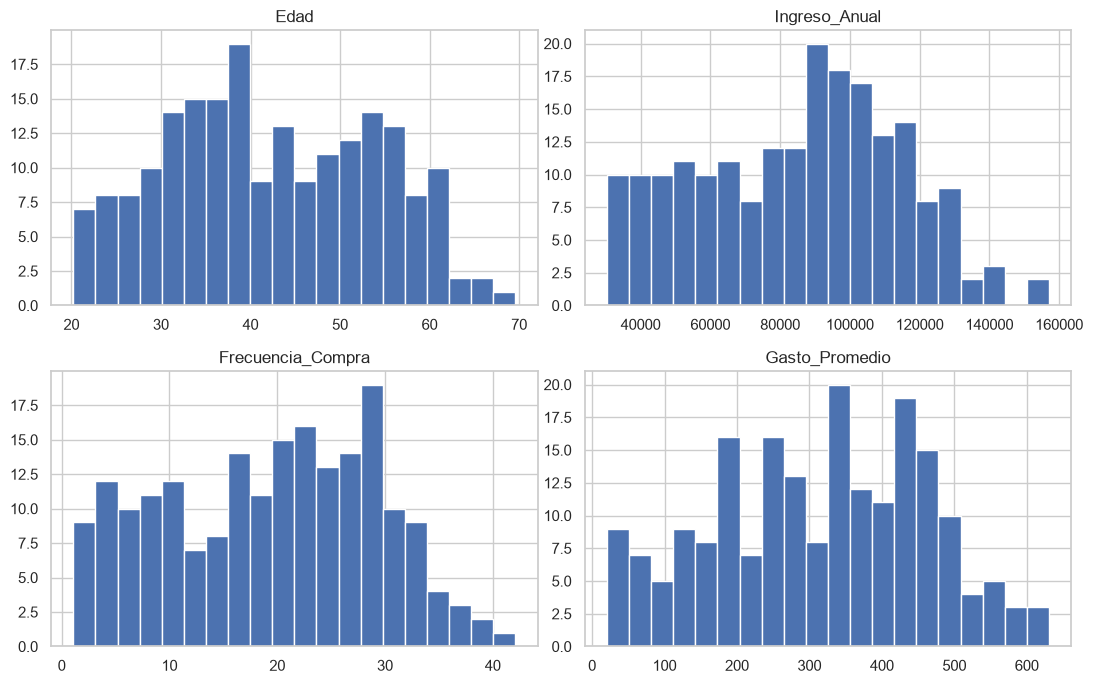

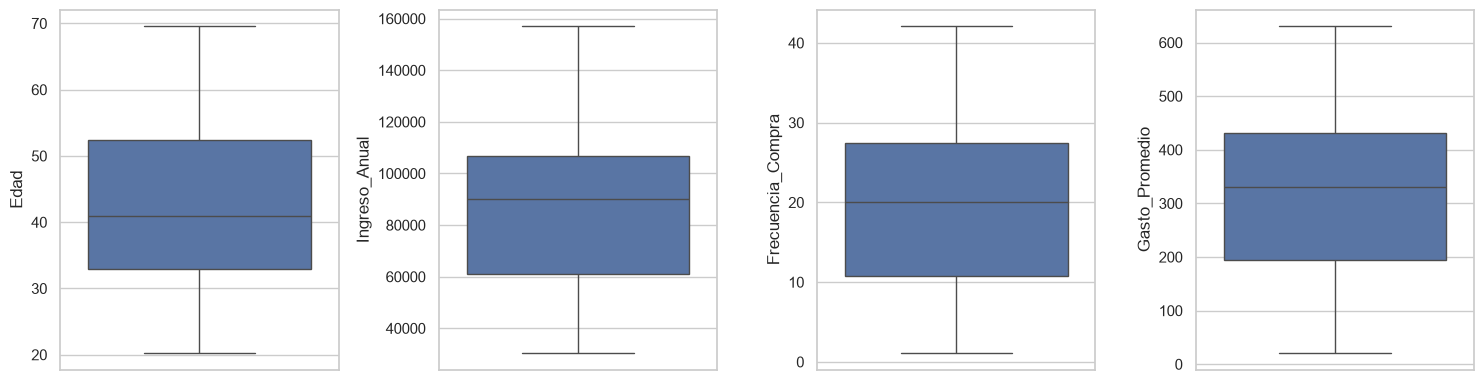

Outliers (regla 1.5·IQR):
Edad                 0
Ingreso_Anual        0
Frecuencia_Compra    0
Gasto_Promedio       0
dtype: int64


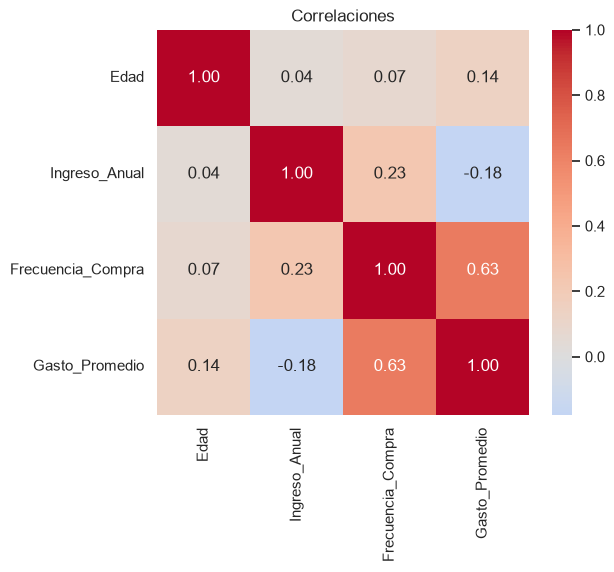

In [27]:
Xb, _ = make_blobs(n_samples=200, n_features=4, centers=5, cluster_std=1.5, random_state=42)
df = pd.DataFrame(Xb, columns=["Edad", "Ingreso_Anual", "Frecuencia_Compra", "Gasto_Promedio"])
df["Edad"] = np.abs(df["Edad"]) * 5 + 20
df["Ingreso_Anual"] = np.abs(df["Ingreso_Anual"]) * 10000 + 30000
df["Frecuencia_Compra"] = np.abs(df["Frecuencia_Compra"]) * 3 + 1
df["Gasto_Promedio"] = np.abs(df["Gasto_Promedio"]) * 50 + 20
cols = list(df.columns)
display(df.describe().T.round(2))
df.hist(figsize=(11, 7), bins=20); plt.tight_layout(); plt.show()
fig, axes = plt.subplots(1, 4, figsize=(15, 4))
for ax, col in zip(axes, cols): sns.boxplot(y=df[col], ax=ax)
plt.tight_layout(); plt.show()
q1, q3 = df.quantile(0.25), df.quantile(0.75); iqr = q3 - q1
print("Outliers (regla 1.5·IQR):"); print(((df < q1 - 1.5 * iqr) | (df > q3 + 1.5 * iqr)).sum())
plt.figure(figsize=(6, 5)); sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0); plt.title("Correlaciones"); plt.show()

### 2–3. Preprocesamiento y selección de K

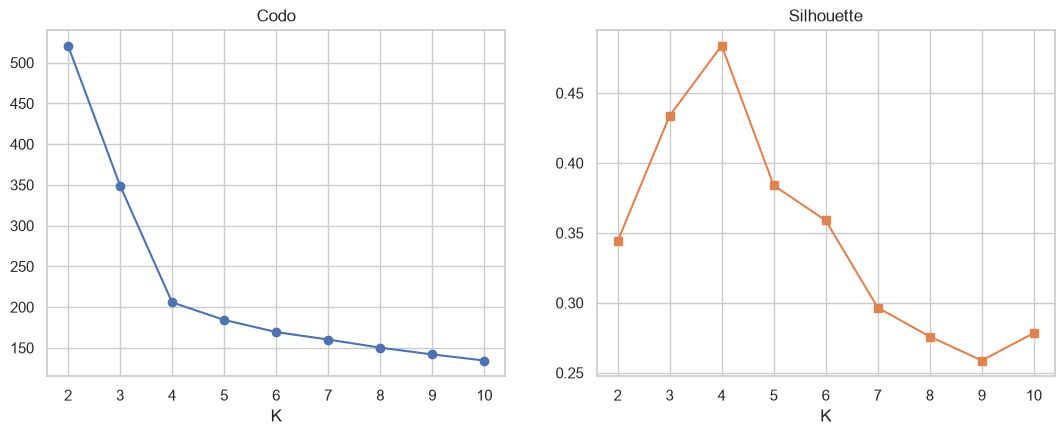

K elegido (máximo silhouette): 4


In [28]:
Xs = StandardScaler().fit_transform(df)
Ks = range(2, 11); inercia, sil = [], []
for k in Ks:
    km = KMeans(k, n_init=10, random_state=RS).fit(Xs); inercia.append(km.inertia_); sil.append(silhouette_score(Xs, km.labels_))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(Ks, inercia, "o-"); axes[0].set_title("Codo"); axes[0].set_xlabel("K")
axes[1].plot(Ks, sil, "s-", color="C1"); axes[1].set_title("Silhouette"); axes[1].set_xlabel("K"); plt.show()
K_OPT = list(Ks)[int(np.argmax(sil))]; print("K elegido (máximo silhouette):", K_OPT)   # puedes fijarlo manualmente si el codo sugiere otro valor

### 4. Clustering y 5. Perfilado

,Edad,Ingreso_Anual,Frecuencia_Compra,Gasto_Promedio,N clientes
Cluster,,,,,
0,54.2,94528.1,23.9,377.6,74
1,33.5,120223.5,14.7,131.7,43
2,41.5,45250.6,6.0,225.4,43
3,30.3,72689.0,30.0,476.7,40


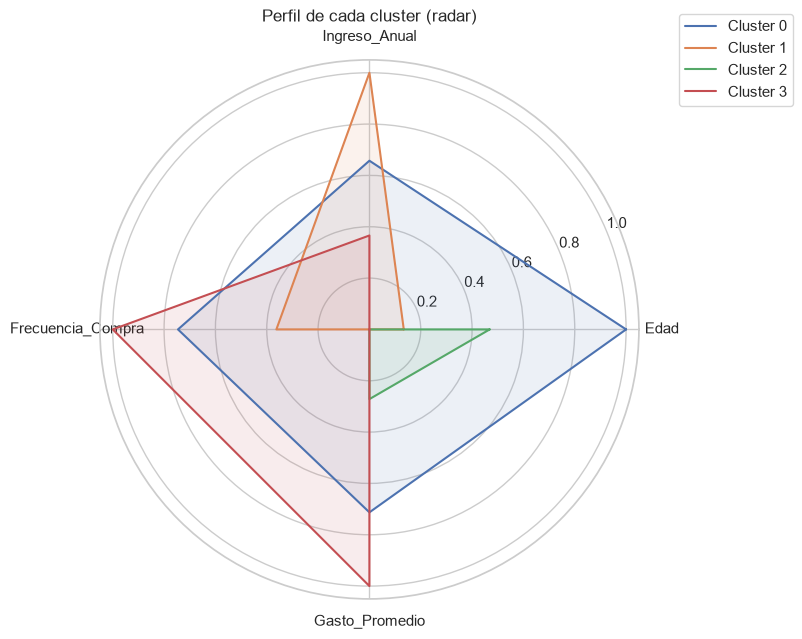

In [29]:
modelo_seg = make_pipeline(StandardScaler(), KMeans(K_OPT, n_init=10, random_state=RS)).fit(df)
df["Cluster"] = modelo_seg.predict(df[cols])
perfil = df.groupby("Cluster")[cols].mean().round(1); perfil["N clientes"] = df.groupby("Cluster").size(); display(perfil)

# Gráfico radar (medias normalizadas 0-1 entre clusters)
norm = (perfil[cols] - perfil[cols].min()) / (perfil[cols].max() - perfil[cols].min() + 1e-9)
ang = np.linspace(0, 2 * np.pi, len(cols), endpoint=False).tolist(); ang += ang[:1]
fig, ax = plt.subplots(figsize=(7, 7), subplot_kw=dict(polar=True))
for cl, fila in norm.iterrows():
    v = fila.tolist() + fila.tolist()[:1]; ax.plot(ang, v, label=f"Cluster {cl}"); ax.fill(ang, v, alpha=0.1)
ax.set_xticks(ang[:-1]); ax.set_xticklabels(cols); ax.set_title("Perfil de cada cluster (radar)"); ax.legend(loc="upper right", bbox_to_anchor=(1.3, 1.1)); plt.show()

### 6. Nombrar los clusters
Se asignan nombres con reglas simples sobre los centroides estandarizados (z > 0 = por encima del promedio). 

,Edad,Ingreso_Anual,Frecuencia_Compra,Gasto_Promedio,Segmento
0,1.02,0.32,0.47,0.45,Clientes Premium (C0)
1,-0.75,1.20,-0.47,-1.23,Potenciales de alto ingreso (C1)
2,-0.06,-1.36,-1.35,-0.59,Compradores ocasionales (C2)
3,-1.02,-0.42,1.08,1.12,Compradores entusiastas (C3)


Segmento
Clientes Premium (C0)               74
Compradores ocasionales (C2)        43
Potenciales de alto ingreso (C1)    43
Compradores entusiastas (C3)        40
Name: count, dtype: int64


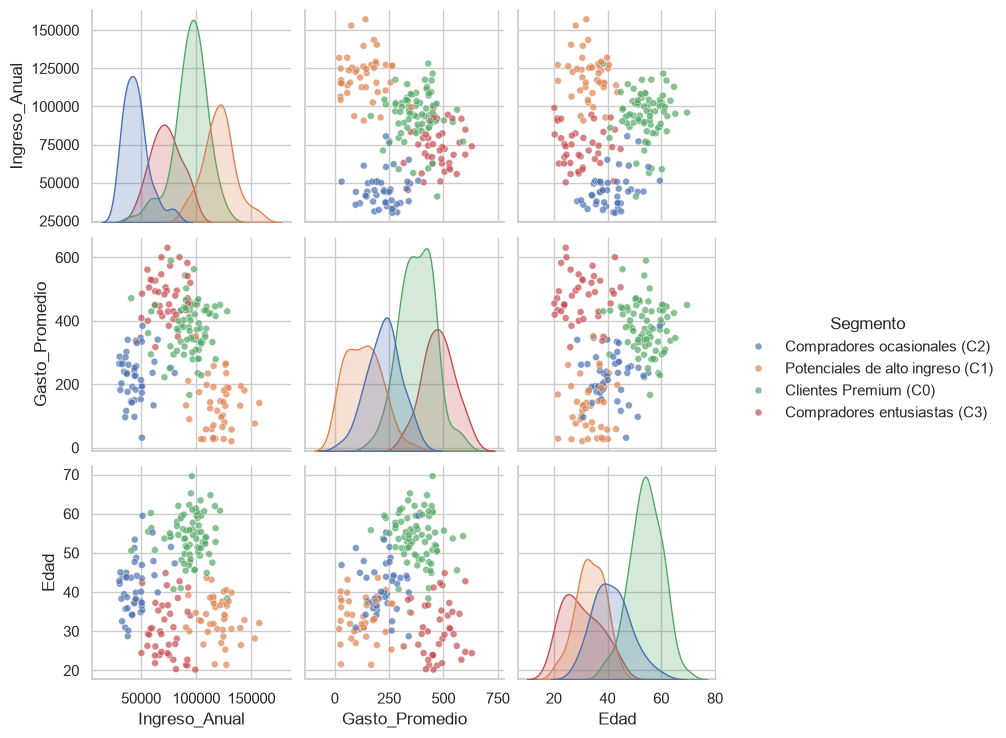

In [30]:
centros_z = pd.DataFrame(modelo_seg[-1].cluster_centers_, columns=cols)
def nombrar(z):
    ing, gas, fre = z.Ingreso_Anual > 0, z.Gasto_Promedio > 0, z.Frecuencia_Compra > 0
    if ing and gas: base = "Clientes Premium"
    elif ing and not gas: base = "Potenciales de alto ingreso"
    elif gas: base = "Compradores entusiastas"
    else: base = "Compradores ocasionales" if not fre else "Compradores frecuentes de bajo gasto"
    return base
nombres = {i: f"{nombrar(centros_z.loc[i])} (C{i})" for i in centros_z.index}
# nombres = {0: "Clientes Premium", 1: "Compradores Ocasionales", ...}   # <- descomenta y edita si prefieres tus nombres
df["Segmento"] = df["Cluster"].map(nombres)
display(centros_z.round(2).assign(Segmento=pd.Series(nombres)))
print(df["Segmento"].value_counts())
sns.pairplot(df, vars=["Ingreso_Anual", "Gasto_Promedio", "Edad"], hue="Segmento", plot_kws={"s": 25, "alpha": 0.7}); plt.show()

### 7. Serialización y 8. Despliegue (función de asignación)

In [31]:
joblib.dump({"pipeline": modelo_seg, "columnas": cols, "nombres": nombres}, "models/segmentacion_clientes.joblib")

def asignar_segmento(edad, ingreso_anual, frecuencia_compra, gasto_promedio, ruta="models/segmentacion_clientes.joblib"):
    obj = joblib.load(ruta)
    x = pd.DataFrame([[edad, ingreso_anual, frecuencia_compra, gasto_promedio]], columns=obj["columnas"])
    cl = int(obj["pipeline"].predict(x)[0])
    return {"cluster": cl, "segmento": obj["nombres"][cl]}

print(asignar_segmento(28, 45000, 6, 150))
print(asignar_segmento(50, 120000, 10, 400))
print(asignar_segmento(22, 32000, 2, 30))

{'cluster': 2, 'segmento': 'Compradores ocasionales (C2)'}
{'cluster': 0, 'segmento': 'Clientes Premium (C0)'}
{'cluster': 2, 'segmento': 'Compradores ocasionales (C2)'}


### 9. (Bonus) Interfaz Gradio para la segmentación

In [32]:
import gradio as gr
def interfaz_segmento(edad, ingreso, frecuencia, gasto):
    r = asignar_segmento(edad, ingreso, frecuencia, gasto); return f"Cluster {r['cluster']} → {r['segmento']}"
demo_seg = gr.Interface(fn=interfaz_segmento,
    inputs=[gr.Number(label="Edad", value=35), gr.Number(label="Ingreso anual (S/)", value=60000),
            gr.Number(label="Frecuencia de compra", value=8), gr.Number(label="Gasto promedio (S/)", value=150)],
    outputs=gr.Textbox(label="Segmento asignado"), title="Segmentación de clientes")
demo_seg.launch(share=True)

* Running on local URL:  http://127.0.0.1:7861
* Running on public URL: https://b247cd953593bfcba2.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## Ejercicio 4.2 — Compresión de imágenes con K-Means
Se usa la imagen de ejemplo `flower.jpg` que trae sklearn. Para usar la tuya, pon su ruta en `RUTA_IMAGEN`.


Imagen: (427, 640, 3)


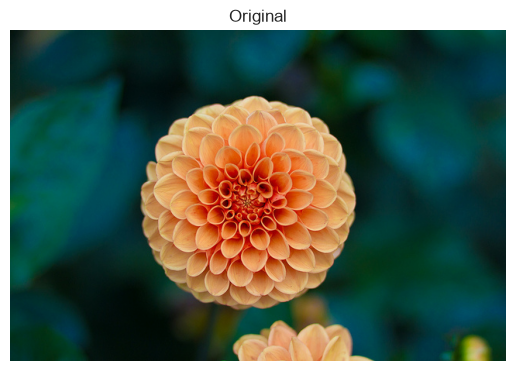

In [33]:
RUTA_IMAGEN = None      # p. ej. "mi_foto.jpg"
if RUTA_IMAGEN:
    img = plt.imread(RUTA_IMAGEN)[..., :3]; img = img / 255.0 if img.dtype == np.uint8 else img.astype(float)
else:
    img = load_sample_image("flower.jpg") / 255.0
print("Imagen:", img.shape); plt.imshow(img); plt.axis("off"); plt.title("Original"); plt.show()
pixels = img.reshape(-1, 3); N = len(pixels)
muestra = pixels[np.random.RandomState(RS).choice(N, 10000, replace=False)]

,K,MSE,PSNR (dB),Razón de compresión
0,2,0.0111,19.5636,23.9958
1,4,0.0065,21.8792,11.9979
2,8,0.0023,26.3135,7.9981
3,16,0.0011,29.5362,5.9979
4,32,0.0007,31.8542,4.7973
5,64,0.0004,34.0592,3.9963
6,128,0.0002,36.1523,3.4231
7,256,0.0002,38.1679,2.9916


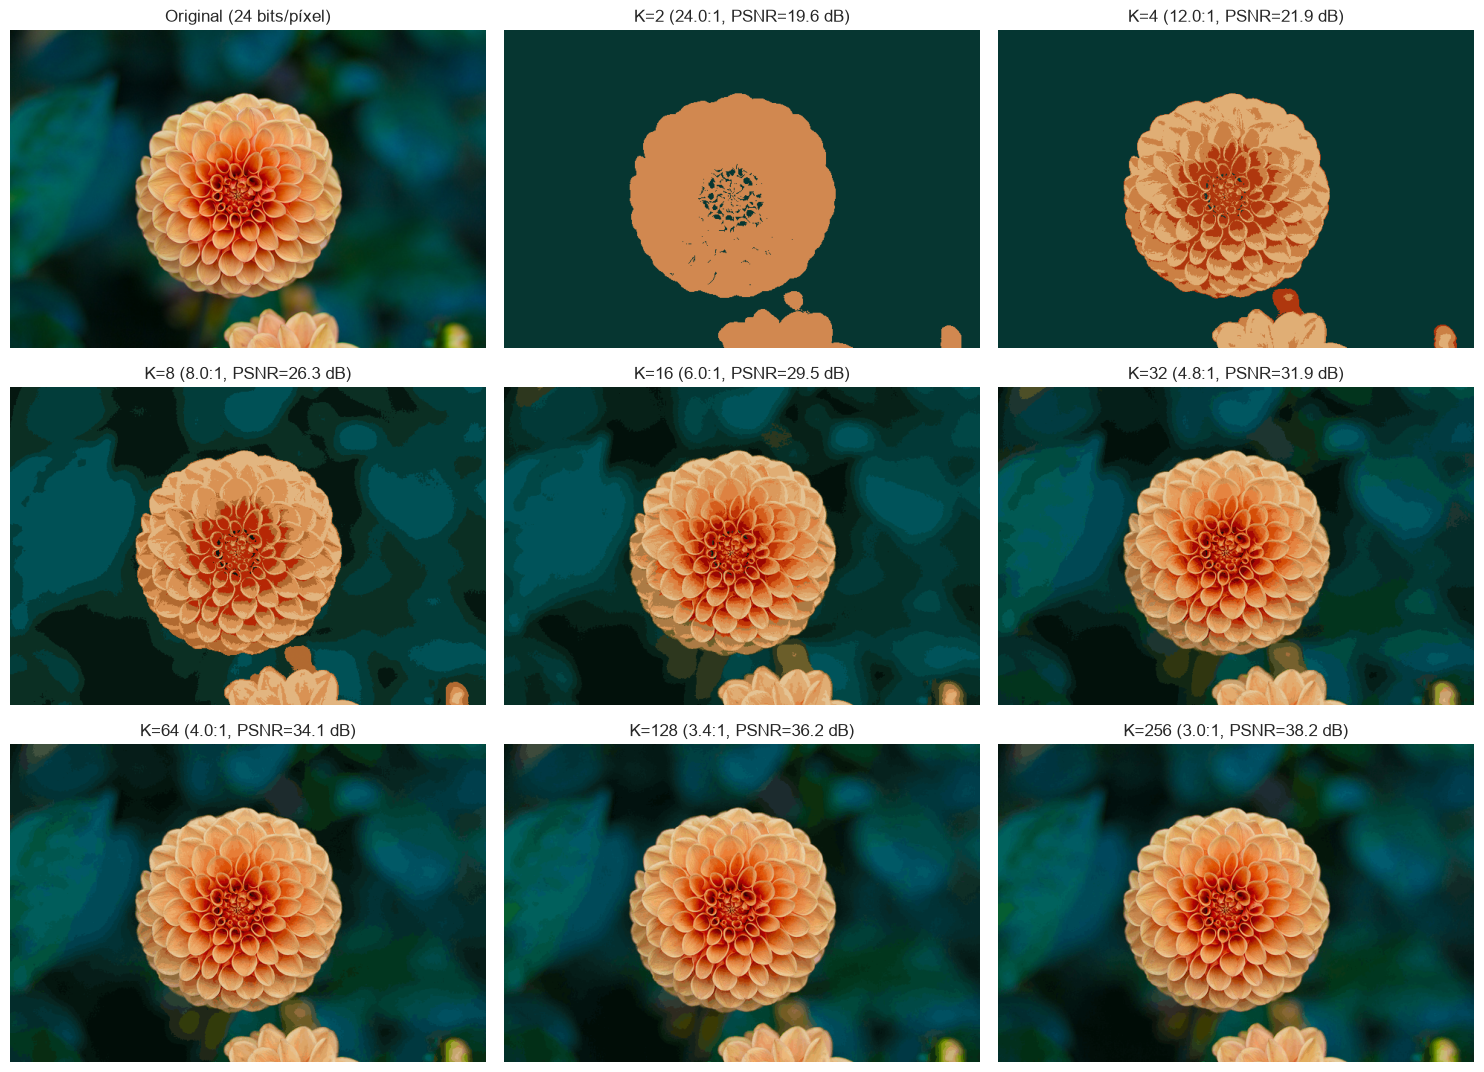

In [34]:
Ks = [2, 4, 8, 16, 32, 64, 128, 256]; recon, filas = {}, []
for K in Ks:
    km = KMeans(n_clusters=K, n_init=1, random_state=RS).fit(muestra)
    labels = km.predict(pixels); comp = km.cluster_centers_[labels].reshape(img.shape); recon[K] = comp
    mse = np.mean((img - comp) ** 2); psnr = 10 * np.log10(1 / mse)
    bits_orig = N * 24; bits_comp = N * int(np.ceil(np.log2(K))) + K * 24       # índices + paleta
    filas.append({"K": K, "MSE": mse, "PSNR (dB)": psnr, "Razón de compresión": bits_orig / bits_comp})
res = pd.DataFrame(filas); display(res.round(4))

fig, axes = plt.subplots(3, 3, figsize=(15, 11))
axes[0, 0].imshow(img); axes[0, 0].set_title("Original (24 bits/píxel)")
for ax, K in zip(axes.ravel()[1:], Ks):
    ax.imshow(np.clip(recon[K], 0, 1)); ax.set_title(f"K={K} ({res.loc[res.K == K, 'Razón de compresión'].iloc[0]:.1f}:1, PSNR={res.loc[res.K == K, 'PSNR (dB)'].iloc[0]:.1f} dB)")
for ax in axes.ravel(): ax.axis("off")
plt.tight_layout(); plt.show()

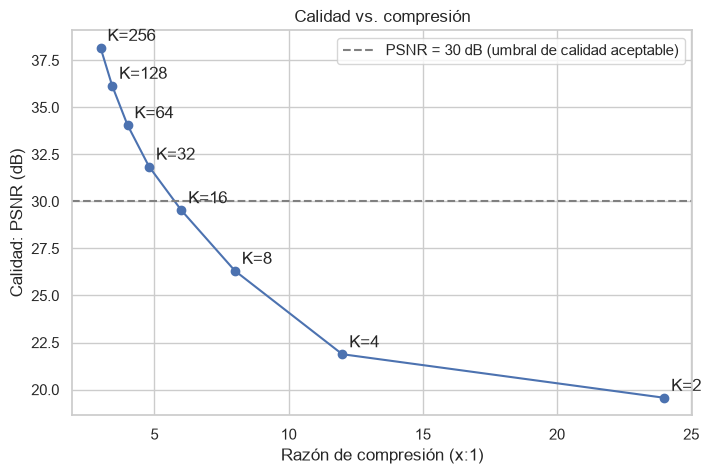

Menor K con PSNR ≥ 30 dB: 32


In [35]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(res["Razón de compresión"], res["PSNR (dB)"], "o-")
for _, r in res.iterrows(): ax.annotate(f"K={int(r.K)}", (r["Razón de compresión"], r["PSNR (dB)"]), textcoords="offset points", xytext=(5, 5))
ax.axhline(30, color="gray", ls="--", label="PSNR = 30 dB (umbral de calidad aceptable)")
ax.set_xlabel("Razón de compresión (x:1)"); ax.set_ylabel("Calidad: PSNR (dB)"); ax.set_title("Calidad vs. compresión"); ax.legend(); plt.show()
k_min = res.loc[res["PSNR (dB)"] >= 30, "K"].min(); print("Menor K con PSNR ≥ 30 dB:", k_min)

**Respuesta 4.2** — A más colores (K) mayor calidad (PSNR sube) pero menor compresión: la razón cae de 24:1 (K=2, 1 bit/píxel) a ≈ 3:1 (K=256, 8 bits/píxel + paleta). En la ejecución de referencia (`flower.jpg`) el PSNR va de ≈ 19.6 dB (K=2) a ≈ 38 dB (K=256) y cruza los 30 dB en **K=32** (≈ 4.8:1). Con **K=2–4** la imagen pierde mucho detalle (posterización fuerte); con **K=16** (≈ 29.5 dB, 6:1) ya se reconoce bien el contenido; con **K=32–64** es casi indistinguible del original. El K mínimo "aceptable" es **subjetivo y depende de la imagen**: suele estar entre **16 y 32**. Fíjate en la celda anterior qué K cruza el umbral de 30 dB en tu imagen.